# Practical Application III: Comparing Classifiers

**Overview**: In this practical application, your goal is to compare the performance of the classifiers we encountered in this section, namely K Nearest Neighbor, Logistic Regression, Decision Trees, and Support Vector Machines.  We will utilize a dataset related to marketing bank products over the telephone.  



### Getting Started

Our dataset comes from the UCI Machine Learning repository [link](https://archive.ics.uci.edu/ml/datasets/bank+marketing).  The data is from a Portugese banking institution and is a collection of the results of multiple marketing campaigns.  We will make use of the article accompanying the dataset [here](CRISP-DM-BANK.pdf) for more information on the data and features.



### Problem 1: Understanding the Data

To gain a better understanding of the data, please read the information provided in the UCI link above, and examine the **Materials and Methods** section of the paper.  How many marketing campaigns does this data represent?

In [ ]:
# [Problem 1] Answer based on the reading materials
# How many marketing campaigns does this data represent?


This data corresponds to one campaign which runs from from May 2008 to November 2010. It is split into four dataset
1) bank-additional-full.csv with all examples (41188) and 20 inputs, ordered by date (from May 2008 to November 2010), very close to the data analyzed in [Moro et al., 2014]
2) bank-additional.csv with 10% of the examples (4119), randomly selected from 1), and 20 inputs.
3) bank-full.csv with all examples and 17 inputs, ordered by date (older version of this dataset with less inputs).
4) bank.csv with 10% of the examples and 17 inputs, randomly selected from 3 (older version of this dataset with less inputs).
The smallest datasets are provided to test more computationally demanding machine learning algorithms (e.g., SVM).

### Problem 2: Read in the Data

Use pandas to read in the dataset `bank-additional-full.csv` and assign to a meaningful variable name.

In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv('/content/data/bank-additional-full.csv', sep=';')

In [ ]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### Problem 3: Understanding the Features


Examine the data description below, and determine if any of the features are missing values or need to be coerced to a different data type.


```
Input variables:
# bank client data:
1 - age (numeric)
2 - job : type of job (categorical: 'admin.','blue-collar','entrepreneur','housemaid','management','retired','self-employed','services','student','technician','unemployed','unknown')
3 - marital : marital status (categorical: 'divorced','married','single','unknown'; note: 'divorced' means divorced or widowed)
4 - education (categorical: 'basic.4y','basic.6y','basic.9y','high.school','illiterate','professional.course','university.degree','unknown')
5 - default: has credit in default? (categorical: 'no','yes','unknown')
6 - housing: has housing loan? (categorical: 'no','yes','unknown')
7 - loan: has personal loan? (categorical: 'no','yes','unknown')
# related with the last contact of the current campaign:
8 - contact: contact communication type (categorical: 'cellular','telephone')
9 - month: last contact month of year (categorical: 'jan', 'feb', 'mar', ..., 'nov', 'dec')
10 - day_of_week: last contact day of the week (categorical: 'mon','tue','wed','thu','fri')
11 - duration: last contact duration, in seconds (numeric). Important note: this attribute highly affects the output target (e.g., if duration=0 then y='no'). Yet, the duration is not known before a call is performed. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model.
# other attributes:
12 - campaign: number of contacts performed during this campaign and for this client (numeric, includes last contact)
13 - pdays: number of days that passed by after the client was last contacted from a previous campaign (numeric; 999 means client was not previously contacted)
14 - previous: number of contacts performed before this campaign and for this client (numeric)
15 - poutcome: outcome of the previous marketing campaign (categorical: 'failure','nonexistent','success')
# social and economic context attributes
16 - emp.var.rate: employment variation rate - quarterly indicator (numeric)
17 - cons.price.idx: consumer price index - monthly indicator (numeric)
18 - cons.conf.idx: consumer confidence index - monthly indicator (numeric)
19 - euribor3m: euribor 3 month rate - daily indicator (numeric)
20 - nr.employed: number of employees - quarterly indicator (numeric)

Output variable (desired target):
21 - y - has the client subscribed a term deposit? (binary: 'yes','no')
```



In [ ]:
# Check for missing values in the DataFrame
missing_values = df.isna().sum()
print("Missing values per column:")
print(missing_values)

Missing values per column:
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64


In [ ]:
# Identify categorical columns and calculate the count and percentage of 'unknown' values
categorical_cols = df.select_dtypes(include=['object', 'category']).columns

unknown_counts = {}
for col in categorical_cols:
    count = (df[col] == 'unknown').sum()
    percentage = (count / len(df)) * 100
    unknown_counts[col] = {'Count': count, 'Percentage (%)': round(percentage, 2)}
unknown_df = pd.DataFrame(unknown_counts).T
display(unknown_df)

,Count,Percentage (%)
job,330.0,0.80
marital,80.0,0.19
education,1731.0,4.20
default,8597.0,20.87
housing,990.0,2.40
loan,990.0,2.40
contact,0.0,0.00
month,0.0,0.00
day_of_week,0.0,0.00
poutcome,0.0,0.00


In [ ]:
# Remove rows where 'default', 'housing', or 'loan' is 'unknown'
df_filtered = df[
    (df['default'] != 'unknown') &
    (df['housing'] != 'unknown') &
    (df['loan'] != 'unknown')
]

# Print shapes to verify the change
print(f"Original shape: {df.shape}")
print(f"Filtered shape: {df_filtered.shape}")

Original shape: (41188, 21)
Filtered shape: (31828, 21)


### Problem 4: Understanding the Task

After examining the description and data, your goal now is to clearly state the *Business Objective* of the task.  State the objective below.

We need to find out based on the data and run through varius classifier model, the predicatability of customer to accept the fixed deposit

In [ ]:
df_filtered.info()

<class 'pandas.core.frame.DataFrame'>
Index: 31828 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             31828 non-null  int64  
 1   job             31828 non-null  object 
 2   marital         31828 non-null  object 
 3   education       31828 non-null  object 
 4   default         31828 non-null  object 
 5   housing         31828 non-null  object 
 6   loan            31828 non-null  object 
 7   contact         31828 non-null  object 
 8   month           31828 non-null  object 
 9   day_of_week     31828 non-null  object 
 10  duration        31828 non-null  int64  
 11  campaign        31828 non-null  int64  
 12  pdays           31828 non-null  int64  
 13  previous        31828 non-null  int64  
 14  poutcome        31828 non-null  object 
 15  emp.var.rate    31828 non-null  float64
 16  cons.price.idx  31828 non-null  float64
 17  cons.conf.idx   31828 non-null  floa

### Problem 5: Engineering Features

Now that you understand your business objective, we will build a basic model to get started.  Before we can do this, we must work to encode the data.  Using just the bank information features, prepare the features and target column for modeling with appropriate encoding and transformations.

In [ ]:
from sklearn.preprocessing import StandardScaler


# 1. Separate features (X) and target (y)
# According to instructions, we should focus on the bank information features or general features for prediction.
# We will drop the 'y' column from our features matrix X.
X = df_filtered.drop(columns=['y'])
y = df_filtered['y'].map({'yes': 1, 'no': 0})

# 2. Identify categorical and numeric columns
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# 3. Apply One-Hot Encoding to categorical features
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

# 4. Scale the numeric columns
scaler = StandardScaler()
X_encoded[numeric_cols] = scaler.fit_transform(X_encoded[numeric_cols])

# Check the preprocessed dataset
print("Encoded Features Shape:", X_encoded.shape)
display(X_encoded.head())


Encoded Features Shape: (31828, 50)


,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,...,month_may,month_nov,month_oct,month_sep,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_nonexistent,poutcome_success
0,1.608150,0.003733,-0.560364,0.215937,-0.373512,0.730971,0.798878,0.867541,0.790167,0.408581,...,True,False,False,False,True,False,False,False,True,False
2,-0.204943,-0.130169,-0.560364,0.215937,-0.373512,0.730971,0.798878,0.867541,0.790167,0.408581,...,True,False,False,False,True,False,False,False,True,False
3,0.081335,-0.417103,-0.560364,0.215937,-0.373512,0.730971,0.798878,0.867541,0.790167,0.408581,...,True,False,False,False,True,False,False,False,True,False
4,1.608150,0.179718,-0.560364,0.215937,-0.373512,0.730971,0.798878,0.867541,0.790167,0.408581,...,True,False,False,False,True,False,False,False,True,False
6,1.894428,-0.463012,-0.560364,0.215937,-0.373512,0.730971,0.798878,0.867541,0.790167,0.408581,...,True,False,False,False,True,False,False,False,True,False


### Problem 6: Train/Test Split

With your data prepared, split it into a train and test set.

In [ ]:
from sklearn.model_selection import train_test_split

# Split the dataset into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)
print("\nClass distribution in Training Set:\n", y_train.value_counts(normalize=True))
print("\nClass distribution in Testing Set:\n", y_test.value_counts(normalize=True))

Training set shape: (25462, 50)
Testing set shape: (6366, 50)

Class distribution in Training Set:
 y
0    0.871141
1    0.128859
Name: proportion, dtype: float64

Class distribution in Testing Set:
 y
0    0.871191
1    0.128809
Name: proportion, dtype: float64


### Problem 7: A Baseline Model

Before we build our first model, we want to establish a baseline.  What is the baseline performance that our classifier should aim to beat?

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

# Establish baseline model (predicting the majority class 'no')
baseline_model = DummyClassifier(strategy='most_frequent')
baseline_model.fit(X_train, y_train)

# Evaluate baseline
train_baseline_acc = baseline_model.score(X_train, y_train)
test_baseline_acc = baseline_model.score(X_test, y_test)

print(f"Baseline Train Accuracy: {train_baseline_acc * 100:.2f}%")
print(f"Baseline Test Accuracy: {test_baseline_acc * 100:.2f}%")


Baseline Train Accuracy: 87.11%
Baseline Test Accuracy: 87.12%


### Problem 8: A Simple Model

Use Logistic Regression to build a basic model on your data.  

In [ ]:
from sklearn.linear_model import LogisticRegression

# Instantiate the Logistic Regression model with a standard max_iter to ensure convergence
log_reg = LogisticRegression(max_iter=1000, random_state=42)

# Fit the model to our training data
log_reg.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


### Problem 9: Score the Model

What is the accuracy of your model?

In [ ]:
# Calculate accuracy scores for the Logistic Regression model
train_log_acc = log_reg.score(X_train, y_train)
test_log_acc = log_reg.score(X_test, y_test)

print(f"Logistic Regression Train Accuracy: {train_log_acc * 100:.2f}%")
print(f"Logistic Regression Test Accuracy: {test_log_acc * 100:.2f}%")


Logistic Regression Train Accuracy: 89.99%
Logistic Regression Test Accuracy: 89.85%


### Problem 10: Model Comparisons

Now, we aim to compare the performance of the Logistic Regression model to our KNN algorithm, Decision Tree, and SVM models.  Using the default settings for each of the models, fit and score each.  Also, be sure to compare the fit time of each of the models.  Present your findings in a `DataFrame` similar to that below:

| Model | Train Time | Train Accuracy | Test Accuracy |
| ----- | ---------- | -------------  | -----------   |
|     |    |.     |.     |

In [ ]:
import time
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

# Initialize lists to store metrics
model_names = ['Logistic Regression', 'K-Nearest Neighbors', 'Decision Tree', 'Support Vector Machine']
train_times = []
train_accs = []
test_accs = []

# Define models with default parameters (using random_state where applicable)
models = [
    LogisticRegression(max_iter=1000, random_state=42),
    KNeighborsClassifier(),
    DecisionTreeClassifier(random_state=42),
    SVC(random_state=42)
]

# Loop through each model, time the fit, and score it
for model in models:
    start_time = time.time()
    model.fit(X_train, y_train)
    end_time = time.time()

    # Measure elapsed time in seconds
    elapsed_time = end_time - start_time
    train_times.append(elapsed_time)

    # Calculate accuracies
    train_acc = model.score(X_train, y_train)
    test_acc = model.score(X_test, y_test)

    train_accs.append(train_acc)
    test_accs.append(test_acc)

# Combine results into a comparison DataFrame
comparison_df = pd.DataFrame({
    'Model': model_names,
    'Train Time (s)': [round(t, 4) for t in train_times],
    'Train Accuracy': [f"{acc * 100:.2f}%" for acc in train_accs],
    'Test Accuracy': [f"{acc * 100:.2f}%" for acc in test_accs]
})

display(comparison_df)


,Model,Train Time (s),Train Accuracy,Test Accuracy
0,Logistic Regression,0.6188,89.99%,89.85%
1,K-Nearest Neighbors,0.0400,92.02%,88.50%
2,Decision Tree,0.2246,100.00%,87.31%
3,Support Vector Machine,12.7590,91.18%,89.77%


### Problem 11: Improving the Model

Now that we have some basic models on the board, we want to try to improve these.  Below, we list a few things to explore in this pursuit.


- Hyperparameter tuning and grid search.  All of our models have additional hyperparameters to tune and explore.  For example the number of neighbors in KNN or the maximum depth of a Decision Tree.  
- Adjust your performance metric

In [ ]:
from sklearn.model_selection import GridSearchCV
import time
import pandas as pd

# Define hyperparameter search spaces for each model
param_grids = {
    'Logistic Regression': {
        'model': LogisticRegression(max_iter=1000, random_state=42),
        'params': {
            'C': [0.01, 0.1, 1, 10],
            'penalty': ['l2']
        }
    },
    'K-Nearest Neighbors': {
        'model': KNeighborsClassifier(),
        'params': {
            'n_neighbors': [3, 5, 9, 15],
            'weights': ['uniform', 'distance']
        }
    },
    'Decision Tree': {
        'model': DecisionTreeClassifier(random_state=42),
        'params': {
            'max_depth': [3, 5, 10, None],
            'min_samples_split': [2, 5, 10]
        }
    },
    'Support Vector Machine': {
        'model': SVC(random_state=42),
        'params': {
            'C': [0.1, 1, 10],
            'kernel': ['linear', 'rbf']
        }
    }
}

tuned_results = []

# Run Grid Search for each model
for name, config in param_grids.items():
    print(f"Tuning {name}...")
    grid_search = GridSearchCV(
        estimator=config['model'],
        param_grid=config['params'],
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )

    start_time = time.time()
    grid_search.fit(X_train, y_train)
    elapsed_time = time.time() - start_time

    best_model = grid_search.best_estimator_
    train_acc = best_model.score(X_train, y_train)
    test_acc = best_model.score(X_test, y_test)

    tuned_results.append({
        'Model': name,
        'Best Params': grid_search.best_params_,
        'Tuning Time (s)': round(elapsed_time, 4),
        'Train Accuracy': f"{train_acc * 100:.2f}%",
        'Test Accuracy': f"{test_acc * 100:.2f}%"
    })

# Compile results into a DataFrame
tuned_comparison_df = pd.DataFrame(tuned_results)
display(tuned_comparison_df)

Tuning Logistic Regression...
Tuning K-Nearest Neighbors...
Tuning Decision Tree...
Tuning Support Vector Machine...


,Model,Best Params,Tuning Time (s),Train Accuracy,Test Accuracy
0,Logistic Regression,"{'C': 1, 'penalty': 'l2'}",6.1450,89.99%,89.85%
1,K-Nearest Neighbors,"{'n_neighbors': 15, 'weights': 'uniform'}",32.8599,90.56%,88.96%
2,Decision Tree,"{'max_depth': 5, 'min_samples_split': 2}",9.4043,90.77%,90.34%
3,Support Vector Machine,"{'C': 1, 'kernel': 'rbf'}",530.6333,91.18%,89.77%


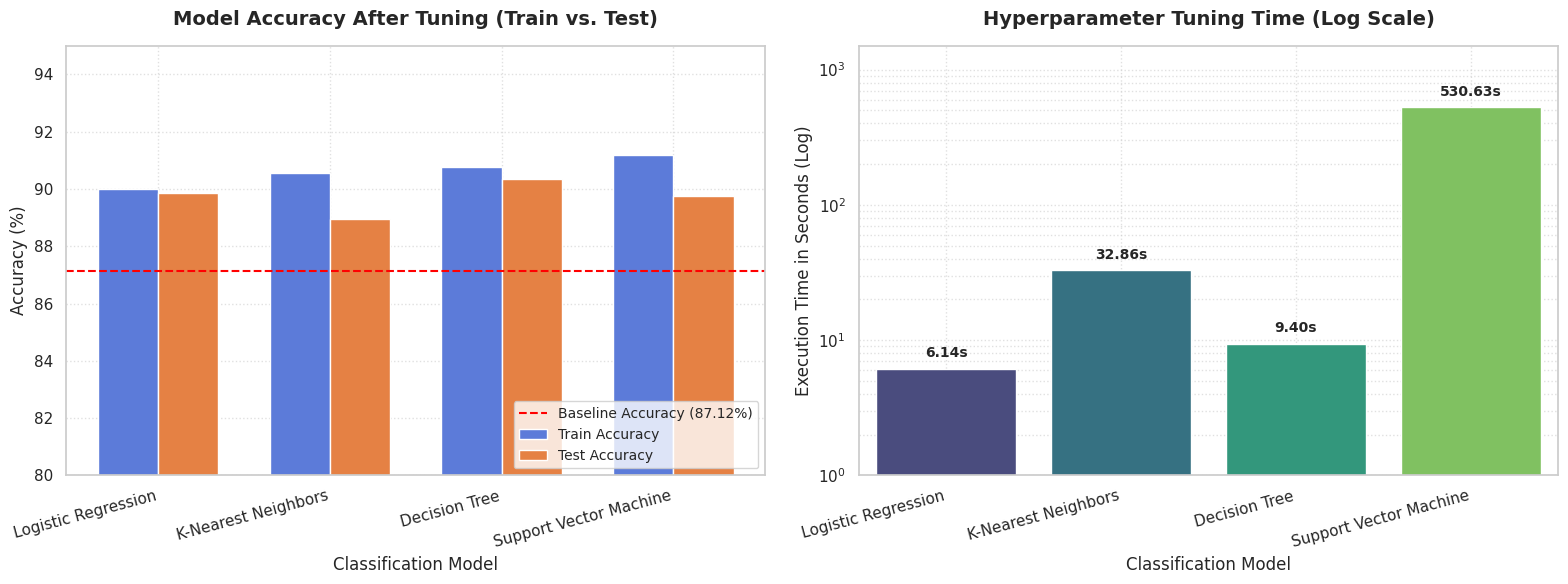

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Extract numeric values from accuracy strings in our dataframe
plot_df = tuned_comparison_df.copy()
plot_df['Train Accuracy (%)'] = plot_df['Train Accuracy'].str.rstrip('%').astype(float)
plot_df['Test Accuracy (%)'] = plot_df['Test Accuracy'].str.rstrip('%').astype(float)

# Set the aesthetic style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Accuracy Comparison (Grouped Bar Chart)
x_indices = np.arange(len(plot_df['Model']))
bar_width = 0.35

axes[0].bar(x_indices - bar_width/2, plot_df['Train Accuracy (%)'], bar_width, label='Train Accuracy', color='#5c7bd9')
axes[0].bar(x_indices + bar_width/2, plot_df['Test Accuracy (%)'], bar_width, label='Test Accuracy', color='#e58144')

# Add baseline horizontal reference line
axes[0].axhline(y=87.12, color='red', linestyle='--', linewidth=1.5, label='Baseline Accuracy (87.12%)')

axes[0].set_title('Model Accuracy After Tuning (Train vs. Test)', fontsize=14, fontweight='bold', pad=15)
axes[0].set_xlabel('Classification Model', fontsize=12)
axes[0].set_ylabel('Accuracy (%)', fontsize=12)
axes[0].set_xticks(x_indices)
axes[0].set_xticklabels(plot_df['Model'], rotation=15, ha='right', fontsize=11)
axes[0].set_ylim(80, 95)
axes[0].legend(loc='lower right', fontsize=10)
axes[0].grid(True, linestyle=':', alpha=0.6)

# Plot 2: Computation Tuning Time (Log Scale for readability due to SVM's high duration)
sns.barplot(x='Model', y='Tuning Time (s)', data=plot_df, ax=axes[1], palette='viridis', hue='Model', legend=False)
axes[1].set_yscale('log')  # Uses a log scale because SVM is orders of magnitude slower

# Add raw values on top of the bars
for i, val in enumerate(plot_df['Tuning Time (s)']):
    axes[1].text(i, val * 1.15, f"{val:.2f}s", ha='center', va='bottom', fontsize=10, fontweight='bold')

axes[1].set_title('Hyperparameter Tuning Time (Log Scale)', fontsize=14, fontweight='bold', pad=15)
axes[1].set_xlabel('Classification Model', fontsize=12)
axes[1].set_ylabel('Execution Time in Seconds (Log)', fontsize=12)

# Fix the tick positions explicitly to eliminate the UserWarning
axes[1].set_xticks(x_indices)
axes[1].set_xticklabels(plot_df['Model'], rotation=15, ha='right', fontsize=11)
axes[1].set_ylim(1, 1500)  # Pad upper limit for text annotations
axes[1].grid(True, which="both", linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

##### Questions